In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from returns import load_log_returns

In [70]:
returns = load_log_returns("historical_data/market_15_assets_10y.csv")

In [86]:
# 1. First, I analyze the matrix shape, for easier analysis I need shape (t_days, n_assets)

returns.shape
n_days = returns.shape[0]
n_assets = returns.shape[1]
print(n_days, n_assets)

2513 15


In [72]:
R = (returns - returns.mean(axis=0)) / returns.std(axis=0, ddof=1)

In [77]:
# 2. The fundament of structural analysis is Singular Value Decomposition SVD

# U contains information about pattern activity over time (how much pattern was 'switch on' during a day
# S gives information about the strength of each pattern, sorted from biggest to smallest
# Vt containts information about patters across stocks

U, S, Vt = np.linalg.svd(R, full_matrices=False)

In [74]:
# k - number of directions
k_list = list(np.arange(1, 16))
variances_over_k = []

for k in k_list:
    S_k = S[:k]
    variance_over_k = float(np.sum(S_k ** 2) / np.sum(S ** 2))
    variances_over_k.append(variance_over_k)
print(variances_over_k)

[0.3361891561192305, 0.46148856737317834, 0.5731348562573075, 0.6655445393926128, 0.7212183552923549, 0.7734050074616657, 0.8076134766048917, 0.8409823991536081, 0.8708283427514725, 0.8983820621319005, 0.9224551467147506, 0.9450199202780378, 0.9669804431900884, 0.9872472531650299, 1.0]


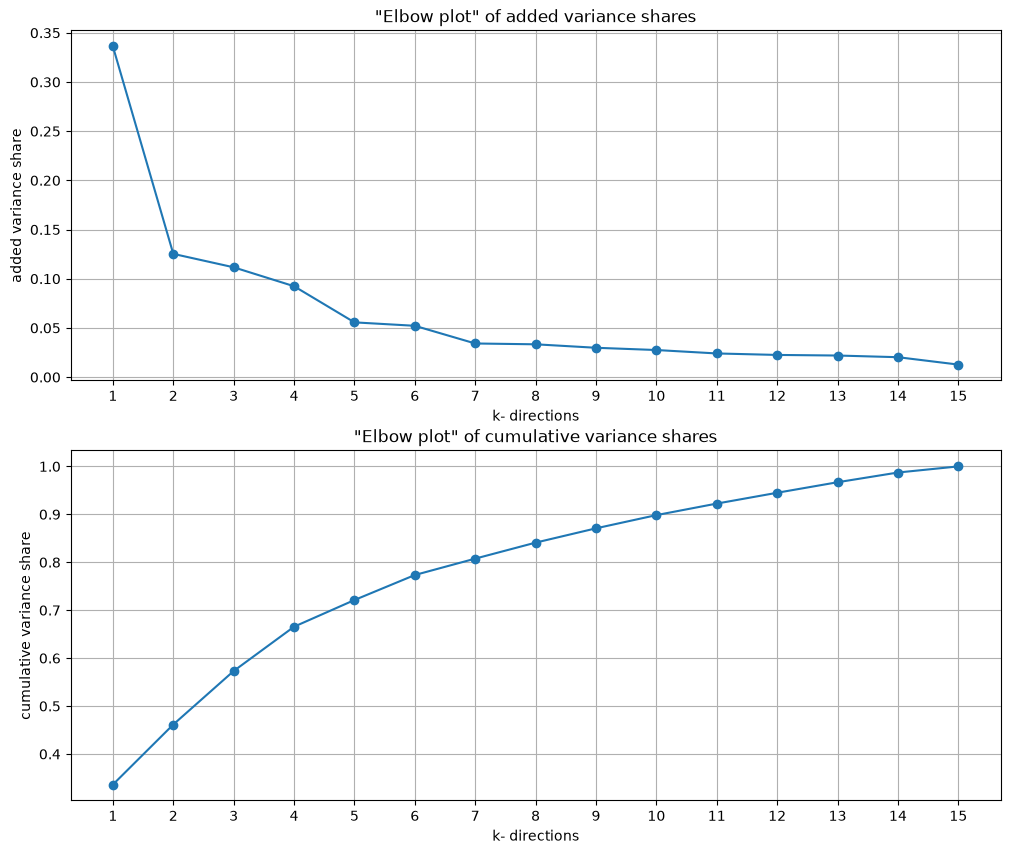

In [75]:
added_variances = np.zeros(len(variances_over_k))
added_variances[0] = variances_over_k[0]
ks = np.arange(1, len(variances_over_k) + 1)

for i in range(1, 15):
    added_variances[i] = variances_over_k[i] - variances_over_k[i-1]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

ax1.plot(ks, added_variances, marker='o')
ax1.grid(True)
ax1.set_title('"Elbow plot" of added variance shares')
ax1.set_xlabel('k- directions')
ax1.set_ylabel('added variance share')

ax2.plot(ks, variances_over_k, marker='o')
ax2.grid(True)
ax2.set_title('"Elbow plot" of cumulative variance shares')
ax2.set_xlabel('k- directions')
ax2.set_ylabel('cumulative variance share')

for ax in (ax1, ax2):
    ax.set_xticks(ks)

plt.show()

In [76]:
# Cutoff choice: k = 4.
# The added variance falls sharply after PC1 (33.6% -> 12.5%) and again after PC4
# (9.2% -> 5.5%); PC5 and PC6 form a flat plateau (~5%), typical of the noise floor.
# Cutting after PC1 would keep only the market factor, so I keep PC1-PC4, i.e. all
# components before the lower plateau.

In [84]:
# 2. Reconstruction
k = 4
U_k, S_k, Vt_k = U[:, :k], np.diag(S[:k]), Vt[:k, :]
reconstructed = U_k @ S_k @ Vt_k
print(np.sum(reconstructed**2) / np.sum(R**2))

0.6655445393926122


In [82]:
# 3. Most extreme day
directions = reconstructed @ Vt_k.T
center = np.mean(directions, axis=0)
distances = directions - center
dist = np.linalg.norm(distances, axis=1)
most_extreme_day = np.argmax(dist)

print(most_extreme_day)

851


In [101]:
from scipy.linalg import subspace_angles

k = 4
threshold = 60
W = 90
window_angles = np.zeros(n_days)

for t in range(W, n_days - W + 1):
  sub_before = R[t - W : t]
  sub_after = R[t : t + W]

  _, _, Vt_before = np.linalg.svd(sub_before, full_matrices=False)
  _, _, Vt_after = np.linalg.svd(sub_after, full_matrices=False)

  base_before = Vt_before[:k].T
  base_after = Vt_after[:k].T

  angles_rad = subspace_angles(base_before, base_after)
  angles_deg = np.degrees(angles_rad)

  window_angles[t] = np.max(angles_deg)

from scipy.signal import find_peaks

transition_days, _ = find_peaks(window_angles, height=threshold, distance=W)
transition_dates = returns.index[transition_days]

print("Detected transition days (based on subspace k=4):")
for d, angle in zip(transition_dates, window_angles[transition_days]):
  print(f"Date: {d.strftime('%Y-%m-%d')} | Max subspace angle: {angle:.2f}°")

Detected transition days (based on subspace k=4):
Date: 2017-06-26 | Max subspace angle: 89.72°
Date: 2017-12-05 | Max subspace angle: 76.78°
Date: 2018-08-31 | Max subspace angle: 87.35°
Date: 2019-02-07 | Max subspace angle: 90.00°
Date: 2019-08-26 | Max subspace angle: 89.41°
Date: 2020-02-03 | Max subspace angle: 88.52°
Date: 2020-09-14 | Max subspace angle: 87.65°
Date: 2021-02-09 | Max subspace angle: 67.38°
Date: 2022-09-08 | Max subspace angle: 84.91°
Date: 2023-02-21 | Max subspace angle: 88.83°
Date: 2023-10-04 | Max subspace angle: 89.58°
Date: 2024-03-06 | Max subspace angle: 89.70°
Date: 2025-03-06 | Max subspace angle: 89.96°
Date: 2025-07-31 | Max subspace angle: 89.30°
Date: 2026-01-30 | Max subspace angle: 89.45°
Date: 2026-06-11 | Max subspace angle: 82.25°


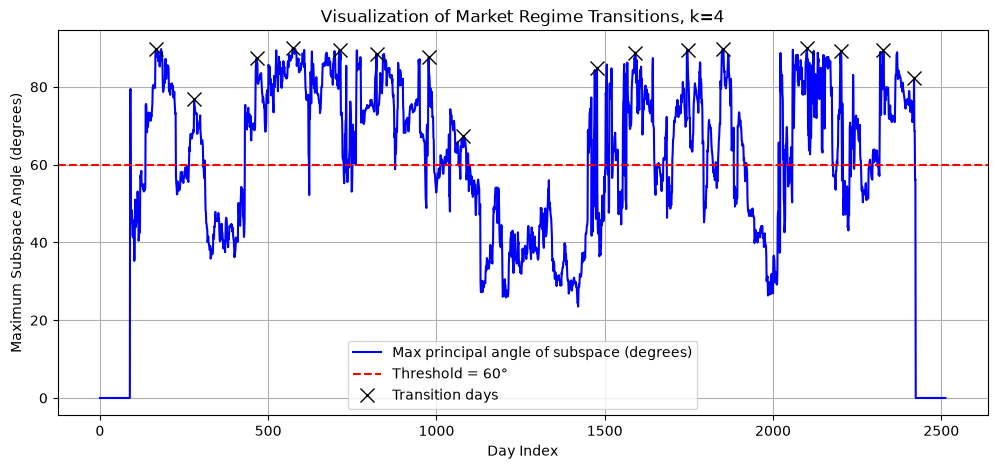

Detected transition days (index -> date -> angle):
Day: 167 | Date: 2017-06-26 | Max degree of subspace: 89.72°
Day: 280 | Date: 2017-12-05 | Max degree of subspace: 76.78°
Day: 466 | Date: 2018-08-31 | Max degree of subspace: 87.35°
Day: 574 | Date: 2019-02-07 | Max degree of subspace: 90.00°
Day: 712 | Date: 2019-08-26 | Max degree of subspace: 89.41°
Day: 822 | Date: 2020-02-03 | Max degree of subspace: 88.52°
Day: 977 | Date: 2020-09-14 | Max degree of subspace: 87.65°
Day: 1079 | Date: 2021-02-09 | Max degree of subspace: 67.38°
Day: 1477 | Date: 2022-09-08 | Max degree of subspace: 84.91°
Day: 1590 | Date: 2023-02-21 | Max degree of subspace: 88.83°
Day: 1746 | Date: 2023-10-04 | Max degree of subspace: 89.58°
Day: 1851 | Date: 2024-03-06 | Max degree of subspace: 89.70°
Day: 2101 | Date: 2025-03-06 | Max degree of subspace: 89.96°
Day: 2202 | Date: 2025-07-31 | Max degree of subspace: 89.30°
Day: 2328 | Date: 2026-01-30 | Max degree of subspace: 89.45°
Day: 2419 | Date: 2026-06-

In [102]:
plt.figure(figsize=(12, 5))
plt.plot(
    window_angles,
    label="Max principal angle of subspace (degrees)",
    color="blue",
)
plt.axhline(
    y=threshold, color="r", linestyle="--", label=f"Threshold = {threshold}°"
)
plt.plot(
    transition_days,
    window_angles[transition_days],
    "x",
    color="black",
    markersize=10,
    label="Transition days",
)
plt.grid(True)
plt.title(
    "Visualization of Market Regime Transitions, k=4"
)
plt.xlabel("Day Index")
plt.ylabel("Maximum Subspace Angle (degrees)")
plt.legend()
plt.show()

transition_dates = returns.index[transition_days]
print("Detected transition days (index -> date -> angle):")
for idx, d, angle in zip(
    transition_days, transition_dates, window_angles[transition_days]
):
  print(
      f"Day: {idx} | Date: {d.strftime('%Y-%m-%d')} | Max degree of subspace:"
      f" {angle:.2f}°"
  )